# México en América Latina: violencia, desigualdad e ingreso (2000–2023)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/benjov/taller-claude-code-cide/blob/main/03-datos/ejemplo-final/mexico_en_america_latina.ipynb)

**Preguntas**
1. ¿Cómo ha evolucionado la tasa de homicidios de México frente al resto de América Latina?
2. ¿Los países más desiguales o de menor ingreso tienen más homicidios?

**Datos:** Indicadores del Desarrollo Mundial (WDI) del Banco Mundial, 17 países, 2000–2023, vía su API pública (sin registro).

> Análisis descriptivo con fines didácticos. **Correlación no es causalidad.**

## 1. Parámetros y datos
`FUENTE_DATOS = "repo"` usa la copia guardada en el repositorio (`../datos/wdi_latam.csv`); `"api"` descarga todo de nuevo del Banco Mundial.
La API a veces tarda o falla: por eso la descarga reintenta y el repositorio guarda una copia con fecha.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

FUENTE_DATOS = "repo"   # "repo" o "api"
PAISES = ["MEX", "ARG", "BOL", "BRA", "CHL", "COL", "CRI", "DOM", "ECU",
          "GTM", "HND", "NIC", "PAN", "PER", "PRY", "SLV", "URY"]
INDICADORES = {
    "VC.IHR.PSRC.P5": "homicidios",     # homicidios intencionales por 100,000 habitantes
    "NY.GDP.PCAP.PP.KD": "pib_pc",      # PIB per cápita, PPA (dólares internacionales constantes de 2021)
    "SI.POV.GINI": "gini",              # índice de Gini
    "SL.UEM.TOTL.ZS": "desempleo",      # desempleo, % de la fuerza laboral (estimación OIT)
}
ANIOS = "2000:2023"
COPIA_REPO = Path("../datos/wdi_latam.csv")
URL_REPO = "https://github.com/benjov/taller-claude-code-cide/raw/main/03-datos/datos/wdi_latam.csv"

def descarga_wdi(indicador, intentos=4):
    url = (f"https://api.worldbank.org/v2/country/{';'.join(PAISES)}/indicator/{indicador}"
           f"?format=json&date={ANIOS}&per_page=2000")
    for i in range(intentos):
        try:
            r = requests.get(url, timeout=60)
            r.raise_for_status()
            return pd.DataFrame([{"iso3": x["countryiso3code"], "pais": x["country"]["value"],
                                  "anio": int(x["date"]), "indicador": indicador, "valor": x["value"]}
                                 for x in r.json()[1]])
        except (requests.RequestException, ValueError, IndexError) as e:
            print(f"  intento {i+1} falló ({type(e).__name__}); reintentando…")
            time.sleep(5 * (i + 1))
    raise RuntimeError(f"No se pudo descargar {indicador}")

if FUENTE_DATOS == "api":
    largo = pd.concat([descarga_wdi(k) for k in INDICADORES])
    origen = "API del Banco Mundial (descarga nueva)"
elif COPIA_REPO.exists():
    largo, origen = pd.read_csv(COPIA_REPO), f"copia del repositorio ({COPIA_REPO})"
else:
    largo, origen = pd.read_csv(URL_REPO), "copia del repositorio (GitHub)"

NOMBRES = {"MEX": "México", "ARG": "Argentina", "BOL": "Bolivia", "BRA": "Brasil", "CHL": "Chile",
           "COL": "Colombia", "CRI": "Costa Rica", "DOM": "Rep. Dominicana", "ECU": "Ecuador",
           "GTM": "Guatemala", "HND": "Honduras", "NIC": "Nicaragua", "PAN": "Panamá", "PER": "Perú",
           "PRY": "Paraguay", "SLV": "El Salvador", "URY": "Uruguay"}
largo["pais"] = largo.iso3.map(NOMBRES)   # la API entrega los nombres en inglés
df = (largo.assign(var=largo.indicador.map(INDICADORES))
           .pivot_table(index=["iso3", "pais", "anio"], columns="var", values="valor").reset_index())
print(f"Origen: {origen} · {df.iso3.nunique()} países · {df.anio.min()}–{df.anio.max()}")
df.head()

Origen: copia del repositorio (../datos/wdi_latam.csv) · 17 países · 2000–2023


var,iso3,pais,anio,desempleo,gini,homicidios,pib_pc
0,ARG,Argentina,2000,15.000,51.0,NaN,22281.381430
1,ARG,Argentina,2001,17.320,53.3,8.316318,21066.458129
2,ARG,Argentina,2002,19.590,53.8,9.387486,18571.702047
3,ARG,Argentina,2003,15.360,51.0,7.721680,20005.138511
4,ARG,Argentina,2004,13.522,48.5,6.023302,21591.449397


## 2. ¿Qué datos faltan? (revisar antes de graficar)
Porcentaje de años con dato por país e indicador. Un promedio regional calculado con huecos puede engañar.

In [2]:
cobertura = (df.groupby("pais")[list(INDICADORES.values())]
               .apply(lambda g: g.notna().mean() * 100).round(0).astype(int)
               .sort_values("homicidios"))
cobertura.style.background_gradient(cmap="Blues", vmin=0, vmax=100).format("{}%")

var,homicidios,pib_pc,gini,desempleo
pais,,,,
Bolivia,38%,100%,92%,100%
Perú,46%,100%,100%,100%
Chile,83%,100%,42%,100%
Ecuador,83%,100%,92%,100%
Nicaragua,88%,100%,17%,100%
Guatemala,92%,100%,17%,100%
Rep. Dominicana,96%,100%,100%,100%
Argentina,96%,100%,96%,100%
El Salvador,96%,100%,96%,100%


## 3. Homicidios: México frente a la región

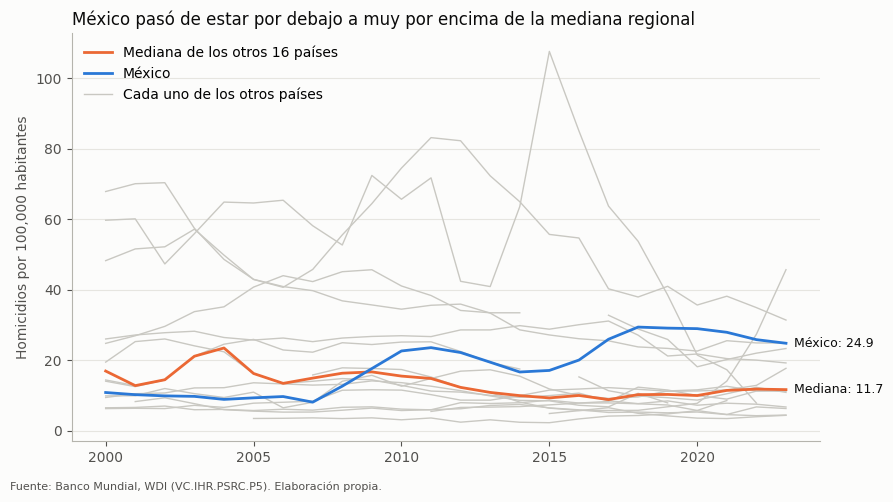

México: 10.9 (2000) → mínimo 8.2 (2007) → máximo 29.4 (2018) → 24.9 (2023)


In [3]:
AZUL, NARANJA, GRIS, TINTA, TINTA2 = "#2a78d6", "#eb6834", "#c9c8c2", "#0b0b0b", "#52514e"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#b5b4ad", "axes.labelcolor": TINTA2,
                     "xtick.color": TINTA2, "ytick.color": TINTA2, "figure.facecolor": "#fcfcfb",
                     "axes.facecolor": "#fcfcfb"})

hom = df.pivot(index="anio", columns="iso3", values="homicidios")
mediana = hom.drop(columns="MEX").median(axis=1)

fig, ax = plt.subplots(figsize=(9, 5))
for iso in hom.columns.drop("MEX"):
    ax.plot(hom.index, hom[iso], color=GRIS, lw=1, zorder=1)
ax.plot(mediana.index, mediana, color=NARANJA, lw=2, label="Mediana de los otros 16 países", zorder=2)
ax.plot(hom.index, hom["MEX"], color=AZUL, lw=2, label="México", zorder=3)
ax.plot([], [], color=GRIS, lw=1, label="Cada uno de los otros países")
for serie, color, nombre in [(hom["MEX"].dropna(), AZUL, "México"), (mediana.dropna(), NARANJA, "Mediana")]:
    ax.annotate(f"{nombre}: {serie.iloc[-1]:.1f}", (serie.index[-1], serie.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=TINTA, fontsize=9)
ax.set_ylabel("Homicidios por 100,000 habitantes")
ax.set_title("México pasó de estar por debajo a muy por encima de la mediana regional",
             loc="left", color=TINTA, fontsize=12)
ax.grid(axis="y", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left")
fig.text(0.01, 0.01, "Fuente: Banco Mundial, WDI (VC.IHR.PSRC.P5). Elaboración propia.", fontsize=8, color=TINTA2)
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig("fig1_homicidios_tendencia.png", dpi=150); plt.show()

mx = hom["MEX"]
print(f"México: {mx.loc[2000]:.1f} (2000) → mínimo {mx.min():.1f} ({mx.idxmin()}) → máximo {mx.max():.1f} ({mx.idxmax()}) → {mx.dropna().iloc[-1]:.1f} ({mx.dropna().index[-1]})")

## 4. El año más reciente, país por país

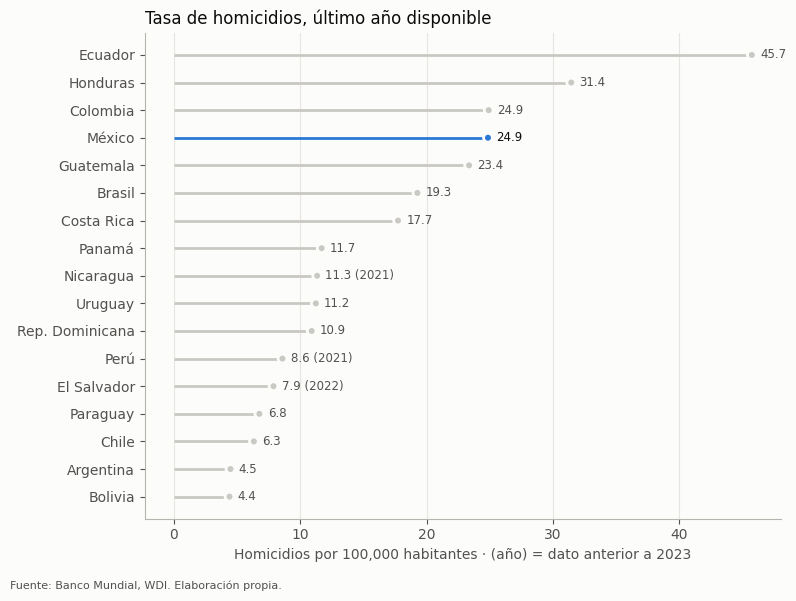

In [4]:
ultimo = (df.dropna(subset=["homicidios"]).sort_values("anio").groupby("iso3").tail(1)
            .sort_values("homicidios"))
fig, ax = plt.subplots(figsize=(8, 6))
colores = [AZUL if i == "MEX" else GRIS for i in ultimo.iso3]
ax.hlines(ultimo.pais, 0, ultimo.homicidios, color=colores, lw=2)
ax.scatter(ultimo.homicidios, ultimo.pais, color=colores, s=40, zorder=3, edgecolor="#fcfcfb", linewidth=2)
for _, r in ultimo.iterrows():
    ax.annotate(f"{r.homicidios:.1f}" + ("" if r.anio == ultimo.anio.max() else f" ({int(r.anio)})"),
                (r.homicidios, r.pais), xytext=(6, 0), textcoords="offset points", va="center",
                fontsize=8.5, color=TINTA if r.iso3 == "MEX" else TINTA2)
ax.set_xlabel("Homicidios por 100,000 habitantes · (año) = dato anterior a 2023")
ax.set_title("Tasa de homicidios, último año disponible", loc="left", color=TINTA, fontsize=12)
ax.grid(axis="x", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
fig.text(0.01, 0.01, "Fuente: Banco Mundial, WDI. Elaboración propia.", fontsize=8, color=TINTA2)
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig("fig2_homicidios_ultimo_anio.png", dpi=150); plt.show()

## 5. ¿Más desigualdad, más homicidios?
Promedio 2015–2023 de cada país (para no depender de un solo año con datos).

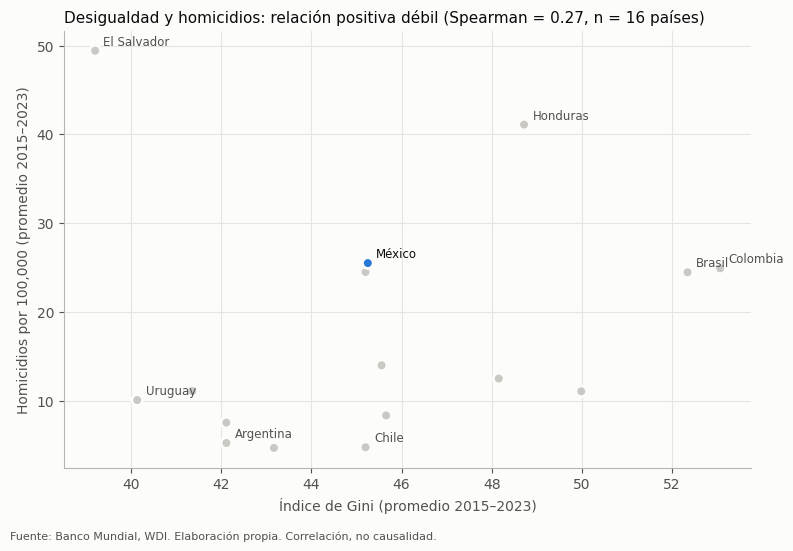

In [5]:
prom = (df[df.anio.between(2015, 2023)].groupby(["iso3", "pais"])[["homicidios", "gini", "pib_pc"]]
          .mean().dropna().reset_index())
rho = prom[["gini", "homicidios"]].corr(method="spearman").iloc[0, 1]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(prom.gini, prom.homicidios, s=60, color=[AZUL if i == "MEX" else GRIS for i in prom.iso3],
           edgecolor="#fcfcfb", linewidth=2, zorder=3)
for _, r in prom.iterrows():
    if r.iso3 in {"MEX", "HND", "SLV", "URY", "CHL", "BRA", "COL", "ARG"}:
        ax.annotate(r.pais, (r.gini, r.homicidios), xytext=(6, 4), textcoords="offset points",
                    fontsize=8.5, color=TINTA if r.iso3 == "MEX" else TINTA2)
ax.set_xlabel("Índice de Gini (promedio 2015–2023)")
ax.set_ylabel("Homicidios por 100,000 (promedio 2015–2023)")
fuerza = "débil" if abs(rho) < 0.3 else ("moderada" if abs(rho) < 0.6 else "fuerte")
signo = "positiva" if rho > 0 else "negativa"
ax.set_title(f"Desigualdad y homicidios: relación {signo} {fuerza} (Spearman = {rho:.2f}, n = {len(prom)} países)",
             loc="left", color=TINTA, fontsize=11)
ax.grid(color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
fig.text(0.01, 0.01, "Fuente: Banco Mundial, WDI. Elaboración propia. Correlación, no causalidad.", fontsize=8, color=TINTA2)
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig("fig3_gini_homicidios.png", dpi=150); plt.show()

## 6. Un modelo simple (y sus límites)
Panel país-año con efectos fijos de país y de año: ¿los cambios en ingreso, desigualdad y desempleo **dentro** de cada país se asocian con cambios en homicidios?
Errores estándar agrupados por país. Con 17 países y muchos huecos, **esto es exploratorio**.

In [6]:
panel = df.dropna(subset=["homicidios", "pib_pc", "gini", "desempleo"]).assign(log_pib=lambda d: np.log(d.pib_pc))
modelo = smf.ols("homicidios ~ log_pib + gini + desempleo + C(iso3) + C(anio)", data=panel).fit(
    cov_type="cluster", cov_kwds={"groups": panel.iso3.astype("category").cat.codes})
tabla = modelo.summary2().tables[1].loc[["log_pib", "gini", "desempleo"], ["Coef.", "Std.Err.", "P>|z|"]].round(3)
print(f"Observaciones: {int(modelo.nobs)} · países: {panel.iso3.nunique()}")
tabla

Observaciones: 292 · países: 17


,Coef.,Std.Err.,P>|z|
log_pib,-13.984,12.364,0.258
gini,-0.157,0.687,0.819
desempleo,1.091,0.827,0.187


## 7. Exportar
Se guardan los datos usados, la tabla de cobertura y la tabla del modelo, para que cualquiera pueda revisar cada número del reporte.

In [7]:
with pd.ExcelWriter("resultados_mexico_al.xlsx") as xls:
    df.to_excel(xls, sheet_name="datos_panel", index=False)
    cobertura.to_excel(xls, sheet_name="cobertura_%")
    ultimo.to_excel(xls, sheet_name="homicidios_ultimo", index=False)
    prom.to_excel(xls, sheet_name="promedios_2015_2023", index=False)
    tabla.to_excel(xls, sheet_name="modelo_efectos_fijos")
print("Listo: resultados_mexico_al.xlsx y 3 figuras PNG")

Listo: resultados_mexico_al.xlsx y 3 figuras PNG


## Lectura y límites
*Cifras con la copia de datos del 22 de noviembre de 2026; si usa `"api"`, verifique que sigan igual.*
- La tasa de homicidios de México **se triplicó** de su mínimo en 2007 (8.2) a 2023 (24.9), con un máximo de 29.4 en 2018. Hasta 2007 estaba por debajo de la mediana regional; hoy la duplica.
- Entre países, la relación entre desigualdad y homicidios es **débil** (Spearman ≈ 0.27). El caso más claro en contra es El Salvador: el Gini más bajo de la muestra y la tasa de homicidios más alta. Brasil y Colombia, los más desiguales, tienen tasas parecidas a la de México.
- En el modelo con efectos fijos, **ningún coeficiente es estadísticamente significativo**: dentro de cada país, los cambios en ingreso, desigualdad o desempleo no explican los cambios en homicidios con estos datos.
- **No es causal:** son 17 países, hay datos faltantes (ver sección 2; un país no tiene Gini suficiente para la figura 3) y el modelo es exploratorio.
- Fuente única (Banco Mundial). Para México conviene contrastar con INEGI (defunciones por homicidio) y con el SESNSP (víctimas reportadas).